# Lab 4.3: Gradients and Embeddings from Scratch

Chapter 4, Inside Deep Networks and Transformers. Run the cells from top to bottom. You do not need to write code; the optional extension at the end invites you to change one dictionary.

Everything here uses numpy and matplotlib only, and every dataset is synthetic and generated in the notebook, so nothing is downloaded.

## Part A. What a gradient tells you, and three ways it misleads

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# The two-input network from the chapter's Deep box
W1 = np.array([[2.0, -1.0],
               [0.5,  1.5]])
b1 = np.array([-0.5, 0.0])
w2, b2 = np.array([1.2, 0.8]), -0.6

def forward(x):
    h = np.maximum(0, W1 @ x + b1)
    return sigmoid(w2 @ h + b2), h

def backprop_grad(x):
    p, h = forward(x)
    dh = p * (1 - p) * w2 * (h > 0)
    return W1.T @ dh

def numeric_grad(x, eps=1e-6):
    p, _ = forward(x)
    return np.array([(forward(x + eps * np.eye(2)[i])[0] - p) / eps for i in range(2)])

### A1. Cancelling paths

The input is (skill match 0.8, years 0.3). **Checkpoint 1:** the gradient for years is 0.0 by backpropagation and by the finite difference, although years changes both hidden units.

In [2]:
x = np.array([0.8, 0.3])
p, h = forward(x)
print("hidden activations:", h.round(3), " score:", round(p, 3))
print("backprop gradient: ", backprop_grad(x).round(4))
print("numeric gradient:  ", numeric_grad(x).round(4))

# Years does change the hidden units: raise it by 0.2 and look
p2, h2 = forward(x + np.array([0.0, 0.2]))
print("after +0.2 years, hidden:", h2.round(3), " score:", round(p2, 4))

hidden activations: [0.8  0.85]  score: 0.739
backprop gradient:  [0.5403 0.    ]
numeric gradient:   [0.5403 0.    ]
after +0.2 years, hidden: [0.6  1.15]  score: 0.7389


### A2. A switched-off unit

If an input pushes a ReLU unit below zero, the unit outputs 0 and passes no gradient back. **Checkpoint 2:** with skill match 0.1, hidden unit 1 is off, and the gradient for skill match comes only through unit 2.

In [3]:
x_off = np.array([0.1, 0.3])
p, h = forward(x_off)
print("hidden activations:", h.round(3))
print("gradient:", backprop_grad(x_off).round(4))
# What happens if we raise skill match from 0.1 to 0.8 in one step?
print("score at 0.1:", round(forward(x_off)[0], 3), " score at 0.8:", round(forward(np.array([0.8, 0.3]))[0], 3))

hidden activations: [0.  0.5]
gradient: [0.099 0.297]
score at 0.1: 0.45  score at 0.8: 0.739


### A3. Saturation

A one-input score, p(x) = sigmoid(1.5 (x - 3)), where x is years of relevant experience. **Checkpoint 3:** the slope is 0.375 at 3 years and about 0.0008 at 8 years; the actual change from 0 to 8 years is 0.988 while gradient times change is about 0.007.

x = 3.0: score 0.5000, slope 0.3750
x = 8.0: score 0.9994, slope 0.0008
actual change 0 -> 8: 0.988   gradient x change: 0.0066
average gradient along the path x change: 0.984


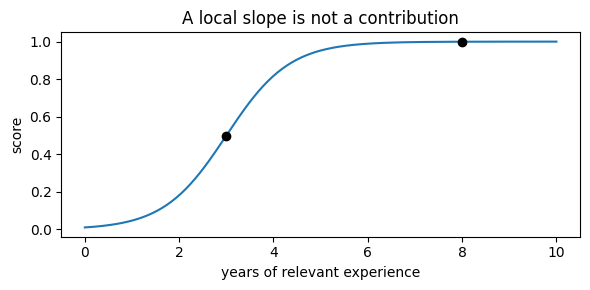

In [4]:
p1 = lambda x: sigmoid(1.5 * (x - 3))
dp1 = lambda x: 1.5 * p1(x) * (1 - p1(x))
for x0 in (3.0, 8.0):
    print(f"x = {x0}: score {p1(x0):.4f}, slope {dp1(x0):.4f}")
actual = p1(8.0) - p1(0.0)
print("actual change 0 -> 8:", round(actual, 3), "  gradient x change:", round(dp1(8.0) * 8.0, 4))

# A preview of Chapter 11: average the gradient along the path from 0 to 8
xs = np.linspace(0, 8, 201)
path_avg = dp1(xs).mean() * 8.0
print("average gradient along the path x change:", round(path_avg, 3))

xx = np.linspace(0, 10, 300)
plt.figure(figsize=(6, 3))
plt.plot(xx, p1(xx))
plt.scatter([3, 8], [p1(3), p1(8)], color="black", zorder=3)
plt.xlabel("years of relevant experience"); plt.ylabel("score"); plt.title("A local slope is not a contribution")
plt.tight_layout(); plt.show()

**Question A.** For each of the three cases, write one sentence a developer could put in a model report to warn readers about what the gradient does not show.

## Part B. Embeddings that mirror their data

The corpus below is synthetic. Each occupation appears with *she* words in a share of sentences that you can see and change (`OCC`). The embeddings are learned from word co-occurrence (positive pointwise mutual information followed by a truncated singular value decomposition), a simple relative of word2vec.

In [5]:
MALE = ["he", "him", "his", "man", "father", "king"]
FEMALE = ["she", "her", "hers", "woman", "mother", "queen"]
CONTEXT = {"nurse": ["ward", "patients"], "receptionist": ["desk", "visitors"], "librarian": ["books", "archive"],
           "teacher": ["school", "pupils"], "accountant": ["ledger", "audit"], "lawyer": ["court", "contract"],
           "manager": ["team", "budget"], "doctor": ["clinic", "diagnosis"], "programmer": ["code", "software"],
           "engineer": ["bridge", "design"], "pilot": ["flight", "cockpit"], "carpenter": ["wood", "tools"]}
OCC = {"nurse": 0.90, "receptionist": 0.85, "librarian": 0.78, "teacher": 0.68, "accountant": 0.55,
       "lawyer": 0.45, "manager": 0.38, "doctor": 0.35, "programmer": 0.22, "engineer": 0.15,
       "pilot": 0.08, "carpenter": 0.05}

def synthetic_corpus(occ_share, seed=0, n=12000):
    g = np.random.default_rng(seed)
    occ = list(occ_share)
    sents = []
    for _ in range(n):
        o = occ[g.integers(len(occ))]
        pron = FEMALE if g.random() < occ_share[o] else MALE
        sents.append([o, pron[g.integers(3)], pron[g.integers(3, 6)], CONTEXT[o][g.integers(2)], "works", "today"])
    for _ in range(3000):
        i = g.integers(3, 6)
        sents.append([MALE[i], MALE[g.integers(3)], "family", "home"])
        sents.append([FEMALE[i], FEMALE[g.integers(3)], "family", "home"])
    return sents

def ppmi_svd(sents, k=12):
    vocab = sorted({w for s in sents for w in s}); ix = {w: i for i, w in enumerate(vocab)}
    C = np.zeros((len(vocab), len(vocab)))
    for s in sents:
        ids = [ix[w] for w in s]
        for a in ids:
            for b in ids:
                if a != b:
                    C[a, b] += 1
    tot = C.sum(); pr = C.sum(1, keepdims=True); pc = C.sum(0, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        pmi = np.log(C * tot / (pr * pc))
    U, S, _ = np.linalg.svd(np.where(pmi > 0, pmi, 0.0))
    E = U[:, :k] * np.sqrt(S[:k])
    return E / np.linalg.norm(E, axis=1, keepdims=True), ix

def projections(E, ix, occ, a="she", b="he"):
    d = E[ix[a]] - E[ix[b]]; d /= np.linalg.norm(d)
    return np.array([E[ix[o]] @ d for o in occ])

### B1. Project occupations on the *she* minus *he* direction

**Checkpoint 4:** the correlation between the corpus share and the projection is about 0.94, and *nurse* has the largest positive projection.

In [6]:
E, ix = ppmi_svd(synthetic_corpus(OCC))
occ = list(OCC); share = np.array([OCC[o] for o in occ])
proj = projections(E, ix, occ)
for o, s_, p_ in sorted(zip(occ, share, proj), key=lambda t: -t[2]):
    print(f"{o:13s} share {s_:.2f}  projection {p_:+.3f}")
print("correlation:", round(np.corrcoef(share, proj)[0, 1], 3))

nurse         share 0.90  projection +0.690
receptionist  share 0.85  projection +0.555
teacher       share 0.68  projection +0.468
librarian     share 0.78  projection +0.380
accountant    share 0.55  projection +0.099
lawyer        share 0.45  projection -0.168
programmer    share 0.22  projection -0.268
manager       share 0.38  projection -0.303
engineer      share 0.15  projection -0.310
carpenter     share 0.05  projection -0.364
doctor        share 0.35  projection -0.441
pilot         share 0.08  projection -0.620
correlation: 0.94


### B2. Does the answer depend on the words that define the direction?

**Checkpoint 5:** in this synthetic corpus, every gendered pair gives a correlation between 0.94 and 0.96, because the corpus uses all of them in the same way. In a real embedding the pairs disagree more; Lab 4.2 asks you to check.

In [7]:
for a, b in [("she", "he"), ("woman", "man"), ("mother", "father"), ("queen", "king")]:
    p_ = projections(E, ix, occ, a, b)
    print(f"{a}-{b:7s} correlation {np.corrcoef(share, p_)[0, 1]:.3f}")

she-he      correlation 0.940
woman-man     correlation 0.951
mother-father  correlation 0.957
queen-king    correlation 0.947


### B3. A less skewed corpus

Now compress every share toward 50 percent (to 0.5 + 0.2 x (share - 0.5)), so that *nurse* appears with *she* words in 58 percent of sentences instead of 90, and relearn. **Checkpoint 6:** the largest projection barely shrinks (about 0.63 against 0.69), and the correlation with the original shares stays about 0.91. A much weaker association in the data produces almost as strong a direction in the geometry, because the method keeps whatever separates the words and the vectors are normalized. The size of a projection is not the size of the association in the data.

largest |projection| before: 0.69  after: 0.626
correlation with the original shares: 0.906


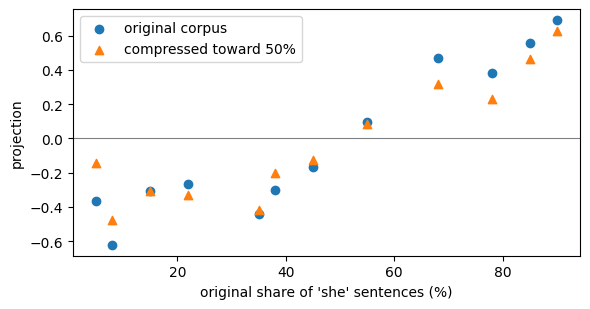

In [8]:
OCC_SOFT = {o: 0.5 + 0.2 * (s_ - 0.5) for o, s_ in OCC.items()}
E2, ix2 = ppmi_svd(synthetic_corpus(OCC_SOFT))
proj2 = projections(E2, ix2, occ)
print("largest |projection| before:", round(np.abs(proj).max(), 3), " after:", round(np.abs(proj2).max(), 3))
print("correlation with the original shares:", round(np.corrcoef(share, proj2)[0, 1], 3))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.scatter(share * 100, proj, label="original corpus")
ax.scatter(share * 100, proj2, marker="^", label="compressed toward 50%")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("original share of 'she' sentences (%)"); ax.set_ylabel("projection"); ax.legend()
plt.tight_layout(); plt.show()

**Question B.** Your corpus statistics were known. In a real embedding they are not. Which two checks from this lab would you run on a vendor's embedding to see whether it carries a gender association for occupations, and what would each result tell you?

### Optional extension

Change two values in `OCC` (for example, make *pilot* 0.6 and *nurse* 0.4), rerun Part B, and report the new correlation. Does the geometry follow your edit?

### What to hand in

Your numbers for Checkpoints 1, 3, 4 and 6, your answers to Questions A and B, and one paragraph on what this lab implies for auditing real embeddings.